# Experiment 5 — Model Training

CSE4007L · Fake News Detection · Krishna Kaushik · 230160223030

**Run `experiment3.ipynb` first** — this notebook needs `train.csv`, `val.csv` and `tfidf.joblib`.

    pip3 install pandas scikit-learn joblib matplotlib

Runtime about 4 minutes (the cross-validation and grid-search cells are the slow ones).


In [1]:
import joblib, pandas as pd, matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

REAL_C, FAKE_C = "#2A6FB5", "#D97706"        # colour-blind-safe pair

def style(ax, title, xlabel):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color="#E6E6E6", lw=0.8); ax.set_axisbelow(True)
    ax.set_title(title, loc="left", fontsize=11); ax.set_xlabel(xlabel, fontsize=9)

def scores(y, p):                    # fake (1) is the positive class
    return [accuracy_score(y, p), precision_score(y, p), recall_score(y, p), f1_score(y, p)]

## 1. Load the prepared data

In [2]:
tr = pd.read_csv("train.csv").dropna()
va = pd.read_csv("val.csv").dropna()
tfidf = joblib.load("tfidf.joblib")          # fitted in Experiment 3

Xtr, ytr = tfidf.transform(tr.text), tr.label
Xva, yva = tfidf.transform(va.text), va.label
print("Train:", Xtr.shape, " Validation:", Xva.shape)
print("Fake share - train:", round(ytr.mean() * 100, 2), "% | val:", round(yva.mean() * 100, 2), "%")

Train: (27056, 50000)  Validation: (5799, 50000)
Fake share - train: 45.16 % | val: 45.18 %


## 2. Baseline and first model

In [3]:
dummy = DummyClassifier(strategy="most_frequent").fit(Xtr, ytr)
print("Majority-class baseline accuracy:", round(dummy.score(Xva, yva), 4))

logreg = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
acc, pre, rec, f1 = scores(yva, logreg.predict(Xva))
print(f"Logistic Regression  acc {acc:.4f}  precision {pre:.4f}  recall {rec:.4f}  f1 {f1:.4f}")

Majority-class baseline accuracy: 0.5482
Logistic Regression  acc 0.9817  precision 0.9883  recall 0.9710  f1 0.9796


## 3. Compare candidate models

              model  accuracy  precision  recall     f1
Logistic Regression    0.9817     0.9883  0.9710 0.9796
         Linear SVM    0.9890     0.9908  0.9847 0.9877
      Random Forest    0.9757     0.9855  0.9603 0.9727


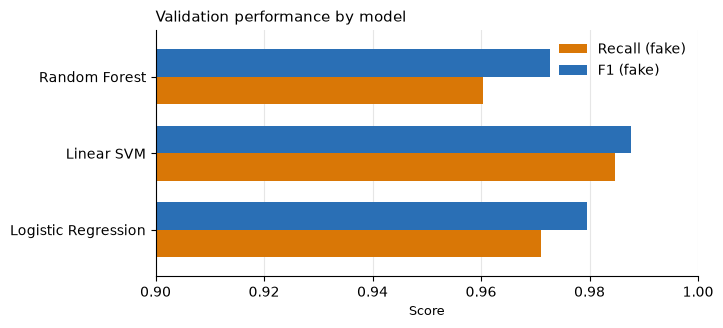

In [4]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM":          LinearSVC(),
    "Random Forest":       RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=42),
}
rows = []
for name, m in models.items():
    m.fit(Xtr, ytr)
    rows.append([name] + scores(yva, m.predict(Xva)))

res = pd.DataFrame(rows, columns=["model", "accuracy", "precision", "recall", "f1"]).round(4)
print(res.to_string(index=False))

ax = res.set_index("model")[["recall", "f1"]].plot.barh(
    color=[FAKE_C, REAL_C], figsize=(7, 3.2), width=0.72)
ax.legend(["Recall (fake)", "F1 (fake)"], frameon=False); ax.set_ylabel("")
ax.set_xlim(0.9, 1.0)
style(ax, "Validation performance by model", "Score")
plt.savefig("fig5_1_models.png", dpi=150, bbox_inches="tight"); plt.show(); plt.close()

## 4. Five-fold cross-validation

In [5]:
for name, m in models.items():
    s = cross_val_score(m, Xtr, ytr, cv=5, scoring="f1", n_jobs=-1)
    print(f"{name:20s} F1 {s.mean():.4f} +/- {s.std():.4f}   folds {s.round(4)}")

Logistic Regression  F1 0.9747 +/- 0.0013   folds [0.9755 0.9763 0.9725 0.974  0.9753]
Linear SVM           F1 0.9836 +/- 0.0012   folds [0.9848 0.9837 0.9815 0.9848 0.9829]
Random Forest        F1 0.9672 +/- 0.0013   folds [0.9678 0.9689 0.9653 0.9681 0.9659]


## 5. Hyperparameter tuning

Logistic Regression  best {'C': 50}  CV F1 0.9823
Linear SVM           best {'C': 5}  CV F1 0.9841

Selected: Linear SVM {'C': 5}
Tuned Linear SVM on validation  acc 0.9888  precision 0.9912  recall 0.9840  f1 0.9876


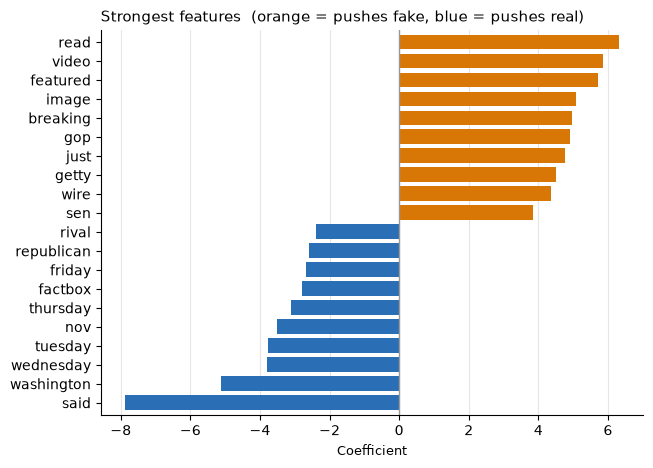

In [6]:
grids = {"Logistic Regression": (LogisticRegression(max_iter=1000), {"C": [1, 5, 10, 50]}),
         "Linear SVM":          (LinearSVC(),                       {"C": [0.1, 0.5, 1, 5]})}
tuned = {}
for name, (m, params) in grids.items():
    g = GridSearchCV(m, params, cv=5, scoring="f1", n_jobs=-1).fit(Xtr, ytr)
    tuned[name] = g
    print(f"{name:20s} best {g.best_params_}  CV F1 {g.best_score_:.4f}")

winner = max(tuned, key=lambda k: tuned[k].best_score_)
best = tuned[winner].best_estimator_
print("\nSelected:", winner, tuned[winner].best_params_)

acc, pre, rec, f1 = scores(yva, best.predict(Xva))
print(f"Tuned {winner} on validation  acc {acc:.4f}  precision {pre:.4f}  recall {rec:.4f}  f1 {f1:.4f}")

coef = pd.Series(best.coef_[0], index=tfidf.get_feature_names_out())
top = pd.concat([coef.nlargest(10), coef.nsmallest(10)]).sort_values()
ax = top.plot.barh(figsize=(7, 5), width=0.78,
                   color=[FAKE_C if v > 0 else REAL_C for v in top])
ax.axvline(0, color="#999999", lw=1)
style(ax, "Strongest features  (orange = pushes fake, blue = pushes real)", "Coefficient")
plt.savefig("fig5_2_coefficients.png", dpi=150, bbox_inches="tight"); plt.show(); plt.close()

## 6. Leak check and save the model

In [7]:
LEAK = ["featured", "image", "images", "pic", "twitter", "com", "getty",
        "realdonaldtrump", "gop", "via", "watch", "video"]
tfidf2 = TfidfVectorizer(max_features=50000,
                         stop_words=list(ENGLISH_STOP_WORDS) + LEAK)
X2tr, X2va = tfidf2.fit_transform(tr.text), tfidf2.transform(va.text)
m2 = clone(best).fit(X2tr, ytr)

print("with boilerplate   :", [round(v, 4) for v in scores(yva, best.predict(Xva))])
print("without boilerplate:", [round(v, 4) for v in scores(yva, m2.predict(X2va))])

joblib.dump(best, "model_best.joblib")
joblib.dump(tuned["Logistic Regression"].best_estimator_, "model_logreg.joblib")
joblib.dump(m2, "model_best_noleak.joblib")
joblib.dump(tfidf2, "tfidf_noleak.joblib")
print("Saved: model_best.joblib, model_logreg.joblib, model_best_noleak.joblib, tfidf_noleak.joblib")

with boilerplate   : [0.9888, 0.9912, 0.984, 0.9876]
without boilerplate: [0.9848, 0.9877, 0.9786, 0.9831]
Saved: model_best.joblib, model_logreg.joblib, model_best_noleak.joblib, tfidf_noleak.joblib
